# 06 · Difference-in-differences

Some units are treated from period `treat_period` on; others never are. Treated units may have
**different levels** to begin with (selection). DiD removes anything that is constant within a unit
or common to all units in a period.

**Key assumption: parallel trends.** Without treatment, treated and control groups would have
moved in parallel. It cannot be tested directly; pre-period event-study coefficients are the usual check.

**You will implement:** the 2×2 DiD from group means, two-way fixed effects (TWFE) by double demeaning,
cluster-robust standard errors, and an event study.

**Library check:** `linearmodels.panel.PanelOLS` with entity and time effects.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS

import causalsim as cs
from causalsim.plotting import use_style, truth_line

use_style()

sim = cs.did_panel(n_units=200, n_periods=20, treat_period=10, effect=3.0, seed=0)
df = sim.data
print(sim)

SimResult(n=4000, cols=['unit', 'period', 'treated', 'post', 'D', 'y'], truth={att=3})


## 1. Two tempting but wrong comparisons

In [2]:
post = df[df.post == 1]
cross_section = post.loc[post.treated == 1, "y"].mean() - post.loc[post.treated == 0, "y"].mean()
tr = df[df.treated == 1]
before_after = tr.loc[tr.post == 1, "y"].mean() - tr.loc[tr.post == 0, "y"].mean()
print(f"treated vs control after treatment: {cross_section:.2f}  (contaminated by selection on level)")
print(f"treated before vs after:            {before_after:.2f}  (contaminated by the common time trend)")

treated vs control after treatment: 5.09  (contaminated by selection on level)
treated before vs after:            5.91  (contaminated by the common time trend)


## 2. From scratch: 2×2 DiD
$\hat\tau = (\bar y_{T,post}-\bar y_{T,pre}) - (\bar y_{C,post}-\bar y_{C,pre})$

2×2 DiD: 3.062   (truth 3.0)


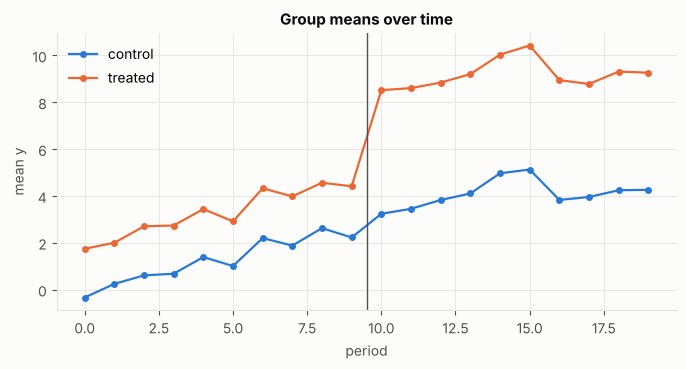

In [3]:
m = df.groupby(["treated", "post"])["y"].mean()
did_2x2 = (m[1, 1] - m[1, 0]) - (m[0, 1] - m[0, 0])
print(f"2×2 DiD: {did_2x2:.3f}   (truth {sim.truth['att']})")

fig, ax = plt.subplots()
for g, label in ((0, "control"), (1, "treated")):
    ax.plot(df[df.treated == g].groupby("period").y.mean(), marker="o", markersize=4, label=label)
ax.axvline(sim.meta["treat_period"] - 0.5, color="#52514e", linewidth=1)
ax.set(title="Group means over time", xlabel="period", ylabel="mean y")
ax.legend()
plt.show()

## 3. From scratch: two-way fixed effects

$y_{it} = \alpha_i + \lambda_t + \tau D_{it} + \varepsilon_{it}$

In a **balanced** panel, the fixed effects can be removed by double demeaning:
$\ddot v_{it} = v_{it} - \bar v_{i\cdot} - \bar v_{\cdot t} + \bar v$. Then $\hat\tau$ is OLS of $\ddot y$ on $\ddot D$.

Observations of the same unit are correlated over time, so standard errors must be **clustered by unit**:
$\widehat{\text{Var}}(\hat\tau) = c\,\dfrac{\sum_g \left(\sum_{t}\ddot D_{gt}e_{gt}\right)^2}{\left(\sum \ddot D^2\right)^2}$,
with small-sample factor $c = \frac{G}{G-1}\cdot\frac{n-1}{n-k}$, where $k$ counts the absorbed fixed effects too.

In [4]:
def two_way_demean(v, unit, period):
    s = pd.DataFrame({"v": v, "u": unit, "t": period})
    return (v - s.groupby("u").v.transform("mean") - s.groupby("t").v.transform("mean") + v.mean()).to_numpy()


def twfe(df, y="y", d="D", unit="unit", period="period"):
    yv, dv = df[y].to_numpy(float), df[d].to_numpy(float)
    yt = two_way_demean(yv, df[unit], df[period])
    dt = two_way_demean(dv, df[unit], df[period])
    tau = dt @ yt / (dt @ dt)
    e = yt - tau * dt
    G, T, n = df[unit].nunique(), df[period].nunique(), len(df)
    k = 1 + (G - 1) + (T - 1) + 1  # tau + unit FE + time FE + intercept
    scores = np.bincount(pd.factorize(df[unit])[0], weights=dt * e)
    c = G / (G - 1) * (n - 1) / (n - k)
    se = np.sqrt(c * np.sum(scores ** 2)) / (dt @ dt)
    return tau, se


tau, se = twfe(df)
print(f"TWFE: {tau:.3f} ± {1.96*se:.3f}")

TWFE: 3.062 ± 0.129


## 4. Library check: PanelOLS
`group_debias=True` applies the same $\frac{G}{G-1}\cdot\frac{n-1}{n-k}$ correction as above (Stata's convention).
Without it, linearmodels uses a slightly different factor. Check what your library does before trusting
a third decimal place.

In [5]:
panel = df.set_index(["unit", "period"])
fit = PanelOLS(panel.y, panel[["D"]], entity_effects=True, time_effects=True).fit(
    cov_type="clustered", cluster_entity=True, group_debias=True
)
np.testing.assert_allclose(tau, fit.params["D"], rtol=1e-10)
np.testing.assert_allclose(se, fit.std_errors["D"], rtol=1e-10)
np.testing.assert_allclose(tau, did_2x2, rtol=1e-10)  # balanced 2x2 timing: TWFE == 2x2 DiD
assert abs(tau - sim.truth["att"]) < 0.2
print("✓ TWFE matches PanelOLS (coefficient and clustered SE) and equals the 2×2 DiD")

✓ TWFE matches PanelOLS (coefficient and clustered SE) and equals the 2×2 DiD


## 5. Event study: checking parallel trends

Replace the single `D` with one dummy per period relative to treatment (for treated units), omitting
period −1 as the reference. Pre-period coefficients should be ≈ 0 if trends were parallel.

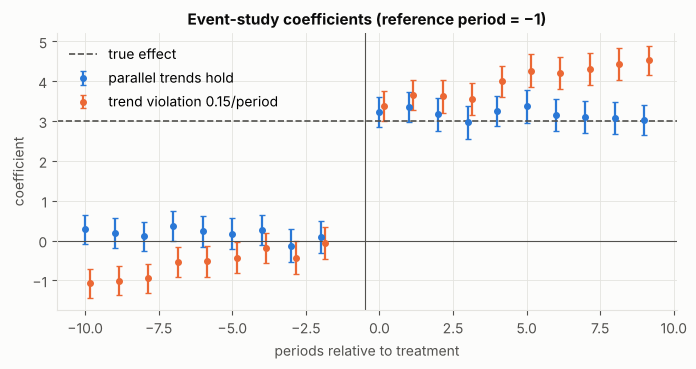

In [6]:
def event_study(df, treat_period, ref=-1):
    rel = (df.period - treat_period).where(df.treated == 1)
    leads_lags = sorted(r for r in rel.dropna().unique() if r != ref)
    D = np.column_stack([(rel == r).to_numpy(float) for r in leads_lags])
    Dt = np.column_stack([two_way_demean(D[:, j], df.unit, df.period) for j in range(D.shape[1])])
    yt = two_way_demean(df.y.to_numpy(float), df.unit, df.period)
    beta = np.linalg.lstsq(Dt, yt, rcond=None)[0]
    e = yt - Dt @ beta
    g = pd.factorize(df.unit)[0]
    S = np.vstack([np.bincount(g, weights=Dt[:, j] * e) for j in range(Dt.shape[1])])  # k × G
    bread = np.linalg.inv(Dt.T @ Dt)
    se = np.sqrt(np.diag(bread @ (S @ S.T) @ bread))
    return pd.DataFrame({"rel_period": leads_lags, "coef": beta, "se": se})


fig, ax = plt.subplots()
for tv, label in ((0.0, "parallel trends hold"), (0.15, "trend violation 0.15/period")):
    s = cs.did_panel(trend_violation=tv, seed=1)
    es = event_study(s.data, s.meta["treat_period"])
    ax.errorbar(es.rel_period + (0.15 if tv else 0), es.coef, yerr=1.96 * es.se, fmt="o", markersize=4, capsize=2, label=label)
ax.axhline(0, color="#52514e", linewidth=0.8)
ax.axhline(3.0, color="#52514e", linewidth=1.2, linestyle="--", label="true effect")
ax.axvline(-0.5, color="#52514e", linewidth=0.8)
ax.set(title="Event-study coefficients (reference period = −1)", xlabel="periods relative to treatment", ylabel="coefficient")
ax.legend()
plt.show()

## 6. Break it

In [7]:
rows = []
for tv in (0.0, 0.05, 0.15):
    s = cs.did_panel(trend_violation=tv, seed=2)
    t_, se_ = twfe(s.data)
    rows.append({"trend violation": tv, "TWFE estimate": t_, "95% CI": f"[{t_-1.96*se_:.2f}, {t_+1.96*se_:.2f}]", "truth": 3.0})
pd.DataFrame(rows)

,trend violation,TWFE estimate,95% CI,truth
0,0.00,2.981295,"[2.85, 3.11]",3.0
1,0.05,3.481295,"[3.35, 3.61]",3.0
2,0.15,4.481295,"[4.35, 4.61]",3.0


**What to notice**

- Selection on *levels* is harmless to DiD; differing *trends* are not, and the bias grows with the post-period length.
- The event study shows the violation as a pre-trend sloping toward period −1, which is your warning sign.

**Exercises**
1. Make treatment timing **staggered** (units start in different periods) with effects that grow over time.
   Show that TWFE can then be badly biased (Goodman-Bacon 2021) and implement a simple fix: compare each cohort
   only with not-yet-treated units.
2. Cluster by period instead of unit. Why is that the wrong choice here?
3. Implement a wild cluster bootstrap for the case of few clusters (e.g. `n_units=12`).